In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

***Task 1***

Use the Palmer penguins dataset (https://archive.ics.uci.edu/dataset/690/palmer+penguins-3). Load it with pandas. Do the following step-by-step:

**a)** Load the data. Report its shape, the type of every feature, and the number of missing values per column.

In [2]:
df_t1 = pd.read_csv("penguins.csv")
df_t1.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [3]:
df_t1.shape

(344, 8)

The dataset has 8 columns and 344 rows.

In [4]:
df_t1.dtypes

species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object

In [5]:
df_t1.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

**b)** Use a boolean mask with two conditions to select all female penguins with a body mass above 4500g. How many are there, and which species do they belong to?

In [6]:
#creating the mask
boolean_mask_1b = (df_t1["sex"] == "female") & (df_t1["body_mass_g"] > 4500)

len(df_t1[boolean_mask_1b])

42

In [7]:
df_t1[boolean_mask_1b]["species"].unique()

<StringArray>
['Gentoo']
Length: 1, dtype: str

There are 42 female penguins with a body mass above 4500g. They are all of the same species 'Gentoo'.

**c)** Use grouping and aggregation to compute, per species, the number of penguins and the mean, median and standard deviation of the body mass. Do mean and median differ noticeably?

In [8]:
#The number of penguins per species
df_t1.groupby("species").size()

species
Adelie       152
Chinstrap     68
Gentoo       124
dtype: int64

In [9]:
#mean of body mass
df_t1.groupby("species")["body_mass_g"].mean()

species
Adelie       3700.662252
Chinstrap    3733.088235
Gentoo       5076.016260
Name: body_mass_g, dtype: float64

In [10]:
#median of body mass
df_t1.groupby("species")["body_mass_g"].median()

species
Adelie       3700.0
Chinstrap    3700.0
Gentoo       5000.0
Name: body_mass_g, dtype: float64

In [11]:
#std of body mass
df_t1.groupby("species")["body_mass_g"].std()

species
Adelie       458.566126
Chinstrap    384.335081
Gentoo       504.116237
Name: body_mass_g, dtype: float64

 For all 3 species the mean is very close to the median considering the std.

**d)** Use aggregation to find how the penguins are distributed over the islands and plot it.

In [12]:
df_t1.groupby("island").size()

island
Biscoe       168
Dream        124
Torgersen     52
dtype: int64

<Axes: xlabel='island'>

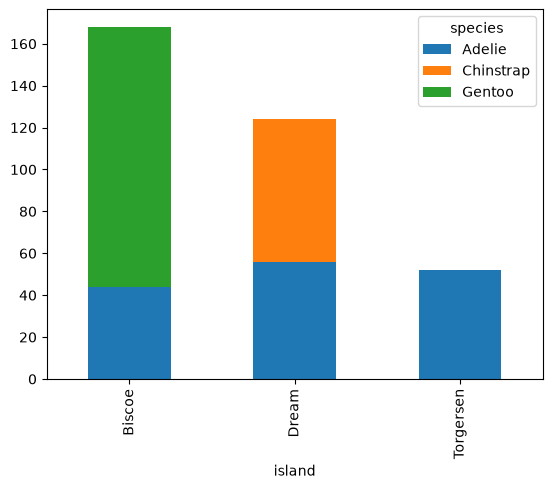

In [13]:
df_t1.groupby(["island", "species"]).size().unstack().plot.bar(stacked = True)

**e)** Merge the data with a small lookup table that you create yourself species → scientific name.

In [14]:
species_lookup = pd.DataFrame({
    "species": ["Adelie", "Chinstrap", "Gentoo"],
    "scientific_name": ["Pygoscelis adeliae", "Pygoscelis antarcticus", "Pygoscelis papua"],
})
species_lookup

,species,scientific_name
0,Adelie,Pygoscelis adeliae
1,Chinstrap,Pygoscelis antarcticus
2,Gentoo,Pygoscelis papua


In [15]:
df_t1_lookup = df_t1.merge(species_lookup, on="species")

In [16]:
df_t1_lookup.shape

(344, 9)

In [17]:
df_t1_lookup["scientific_name"].isna().sum()

np.int64(0)

***Task 2***

For each of the four questions below, name the most suitable chart type, justify your choice in one sentence, and create the plot with matplotlib or seaborn. All datasets can be loaded with pandas.

**i)** How did the number of airline passengers change over the years? (dataset https://www.kaggle.com/datasets/mahoora00135/flights/data)

In [18]:
df_t2i = pd.read_csv("flights.csv")
df_t2i.shape

(336776, 21)

In [19]:
df_t2i.dtypes

id                  int64
year                int64
month               int64
day                 int64
dep_time          float64
sched_dep_time      int64
dep_delay         float64
arr_time          float64
sched_arr_time      int64
arr_delay         float64
carrier               str
flight              int64
tailnum               str
origin                str
dest                  str
air_time          float64
distance            int64
hour                int64
minute              int64
time_hour             str
name                  str
dtype: object

In [20]:
df_t2i["year"].unique()

array([2013])

There is no information regarding passenger numbers and the data set only covers the year 2013, so I am assuming a different dataset was intended for this question.

In [21]:
df_t2i_v2 = sns.load_dataset("flights")

In [22]:
df_t2i_v2.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [23]:
df_t2i_v2["year"].nunique()

12

In [24]:
df_t2i_v2.groupby("year")["passengers"].sum()

year
1949    1520
1950    1676
1951    2042
1952    2364
1953    2700
1954    2867
1955    3408
1956    3939
1957    4421
1958    4572
1959    5140
1960    5714
Name: passengers, dtype: int64

<Axes: xlabel='year', ylabel='passengers'>

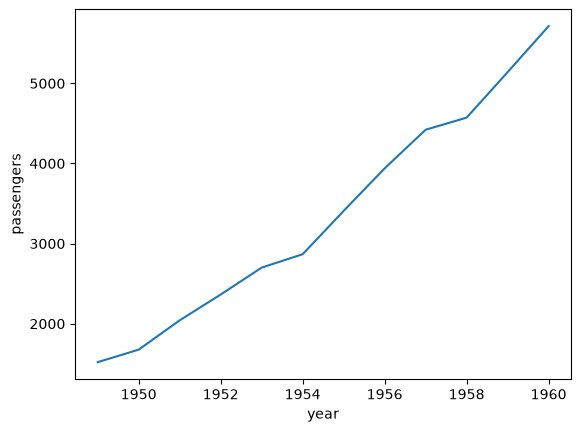

In [25]:
sns.lineplot(data=df_t2i_v2.groupby("year")["passengers"].sum())

I used a lineplot here, because I want to visualize the change year to year.

**ii)** On which day of the week are the tips highest on average? (dataset https://www.kaggle.com/datasets/sakshisatre/tips-dataset)

In [26]:
df_t2ii = pd.read_csv("tip.csv")

<Axes: xlabel='day', ylabel='tip'>

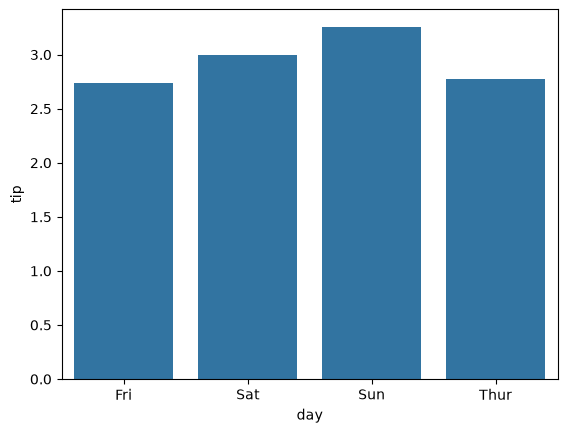

In [27]:
sns.barplot(data=df_t2ii.groupby("day")["tip"].mean())

I used a bar chart, because it makes comparing values very easy.

**iii)** How are the ages of the Titanic passengers distributed? (dataset https://www.kaggle.com/datasets/yasserh/titanic-dataset)

In [28]:
df_t2iii = pd.read_csv("Titanic-Dataset.csv")
df_t2iii.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<Axes: xlabel='Age', ylabel='Density'>

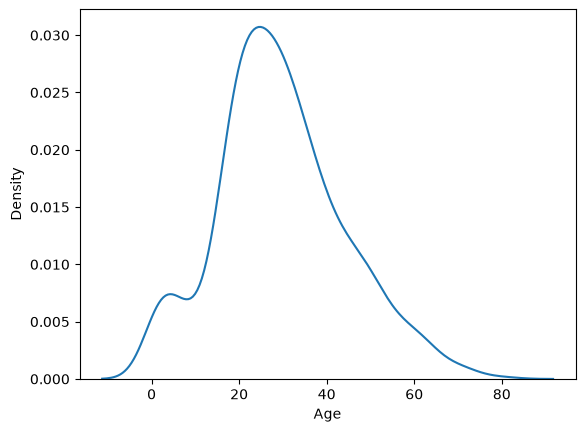

In [29]:
sns.kdeplot(data=df_t2iii["Age"])

<Axes: xlabel='Age', ylabel='Count'>

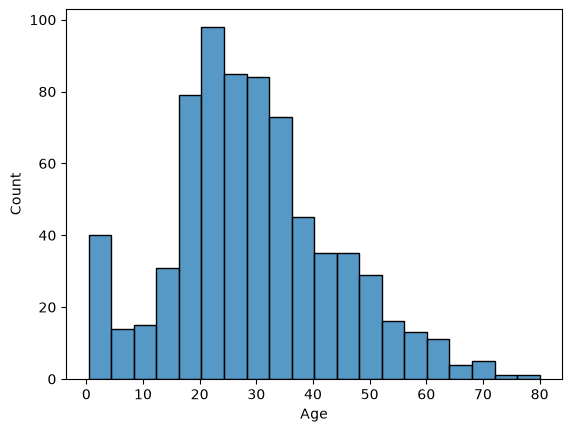

In [30]:
sns.histplot(data=df_t2iii["Age"])

In [31]:
df_t2iii["Age"].mean()

np.float64(29.69911764705882)

In [32]:
df_t2iii["Age"].median()

np.float64(28.0)

In [33]:
df_t2iii["Age"].std()

np.float64(14.526497332334042)

I used a histogram because it is made to visualize distributions of a feature.

**iv)** Is the flipper length of penguins related to their body mass? (dataset penguins)

<Axes: xlabel='flipper_length_mm', ylabel='body_mass_g'>

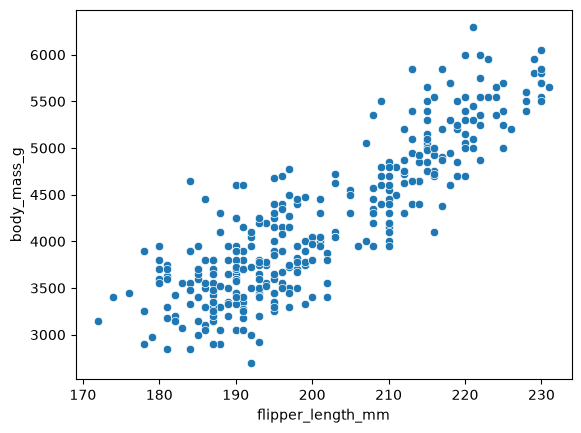

In [34]:
sns.scatterplot(data=df_t1[["flipper_length_mm", "body_mass_g"]], x="flipper_length_mm", y="body_mass_g")

In [35]:
df_t1["flipper_length_mm"].corr(df_t1["body_mass_g"])

np.float64(0.8712017673060114)

There is a very high correlation between body mass and flipper length. A scatterplot is the standard plot to visualize correlations.

***Task 4***

The durations of the trips of a bike-sharing system are right-skewed. Model the population by

In [36]:
rng = np.random.default_rng(0)
population = rng.exponential(scale=10, size=100_000) # minutes

and treat these 100000 values as the whole population.

**a)** Plot a histogram of the population. Compute its mean µ, and standard deviation σ.

<Axes: ylabel='Count'>

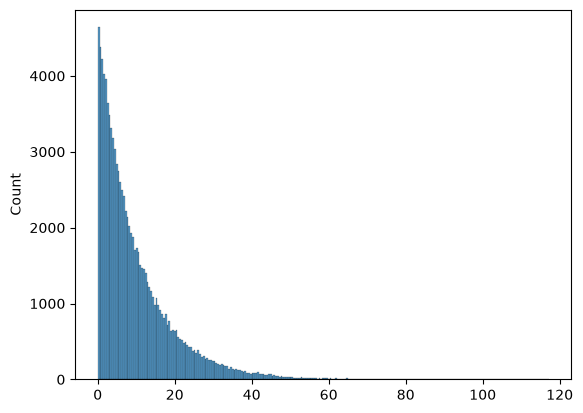

In [37]:
sns.histplot(data=population)

In [38]:
t4a_mean = population.mean()
print(t4a_mean)

9.972351398239269


In [39]:
t4a_std = population.std()
print(t4a_std)

10.019841817781412


**b)** For each n ∈ {5,30,200}, draw 5000 random samples of size n from the population and compute the mean of each sample. Plot the three histograms of the sample means next to each other (same x-axis).

In [40]:
sample_sizes = [5, 30, 200]
means = {}
for n in sample_sizes:
    means[n] = []
    for _ in range(5000):
        means[n].append(rng.choice(population, size=n).mean())
    means[n] = np.array(means[n])

df_t4b = pd.DataFrame(means)

In [41]:
df_t4b.head()

,5,30,200
0,22.129447,8.238482,9.792045
1,7.307006,9.192875,9.870092
2,9.438556,13.048325,10.164181
3,10.306813,9.325779,9.400934
4,6.675121,8.534267,10.948666


<Axes: ylabel='Count'>

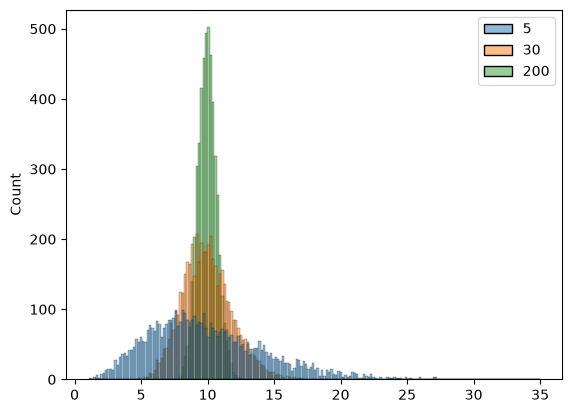

In [42]:
sns.histplot(data=df_t4b)

**c)** For each n, compare the empirical standard deviation of the sample means with σ/√n. Summarize the results in a table.

In [43]:
import math

means_table = pd.DataFrame({
    "n": [5,30,200],
    "std of samples": [df_t4b[5].std(), df_t4b[30].std(), df_t4b[200].std()],
    "σ/√n": [t4a_std / math.sqrt(5), t4a_std / math.sqrt(30), t4a_std / math.sqrt(200)],
})

In [44]:
means_table

,n,std of samples,σ/√n
0,5,4.418243,4.481009
1,30,1.875429,1.829364
2,200,0.706318,0.708510


**d)** Describe how the shape of the histograms changes with n. Which theorem explains this?

The more values the mean is calculated from, the more focused it is around the actual mean of 9.97. This is explained by the Central Limit Theorem. 

***Task 5***

**a)** Before running the code, formulate the null hypothesis H0 and the alternative hypothesis H1 in mathematical notation and in your own words.

In [46]:
import numpy as np
from scipy.stats import norm


def analyse_ab_test(label, purchases_a, visitors_a,
                    purchases_b, visitors_b):
    alpha = 0.05

    rate_a = purchases_a / visitors_a
    rate_b = purchases_b / visitors_b
    difference = rate_b - rate_a
    relative_increase = difference / rate_a

    # Pooled standard error for testing H0: p_A = p_B
    pooled_rate = (
        (purchases_a + purchases_b)
        / (visitors_a + visitors_b)
    )
    se_test = np.sqrt(
        pooled_rate * (1 - pooled_rate)
        * (1 / visitors_a + 1 / visitors_b)
    )
    z = difference / se_test
    p_value = 2 * norm.sf(abs(z))

    # Unpooled standard error for the confidence interval
    se_interval = np.sqrt(
        rate_a * (1 - rate_a) / visitors_a
        + rate_b * (1 - rate_b) / visitors_b
    )
    critical_value = norm.ppf(1 - alpha / 2)
    lower = difference - critical_value * se_interval
    upper = difference + critical_value * se_interval

    print(f"\n{label}")
    print("-" * len(label))
    print(f"Observed conversion rate A: {rate_a:.2%}")
    print(f"Observed conversion rate B: {rate_b:.2%}")
    print(
        "Estimated difference (B - A): "
        f"{100 * difference:.2f} percentage points"
    )
    print(f"Relative increase over A: {relative_increase:.2%}")
    print(f"Test statistic z: {z:.3f}")
    print(f"Two-sided p-value: {p_value:.4g}")
    print(f"Reject H0 at alpha = {alpha}: {p_value < alpha}")
    print(
        "95% confidence interval for p_B - p_A: "
        f"[{100 * lower:.3f}, {100 * upper:.3f}] "
        "percentage points"
    )
    print(
        "Confidence interval width: "
        f"{100 * (upper - lower):.3f} percentage points"
    )


analyse_ab_test(
    "Original experiment",
    purchases_a=500, visitors_a=5000,
    purchases_b=575, visitors_b=5000
)

analyse_ab_test(
    "Larger experiment, same observed conversion rates",
    purchases_a=5000, visitors_a=50000,
    purchases_b=5750, visitors_b=50000
)

ModuleNotFoundError: No module named 'scipy'